UNIVERSIDAD AUTÓNOMA DE OCCIDENTE
FACULTAD DE INGENIERÍA Y CIENCIAS BÁSICAS
INGENIERÍA DE DATOS E INTELIGENCIA ARTIFICIAL
Proyecto Integrador: Arquitectura ETL Automatizada, Orquestada y Gobernada para el Análisis Contextual de la Salud Pública en Colombia (2015–2024)
Asignatura: Ingeniería de Datos (ETL)

Docente: M.Sc. Daniel Felipe Romero Bernal

Estudiantes / Autores: Jheffrey Urbano Garcés - Alexander Mosquera Fajardo

Santiago de Cali, 2026

Nota Introductoria y Propósito del Trabajo
"La ingeniería de datos no se limita al almacenamiento masivo de información; su verdadero valor radica en la capacidad de transformar registros crudos, aislados y heterogéneos en un ecosistema analítico confiable, transparente y éticamente depurado que oriente la toma de decisiones estratégicas en beneficio de la sociedad."

En la primera etapa de este proceso investigativo y académico, logramos estructurar y modelar bajo un esquema dimensional en estrella los registros históricos de presuntos suicidios en Colombia, proporcionando una base relacional robusta en PostgreSQL alineada con el Objetivo de Desarrollo Sostenible (ODS) 3: Salud y Bienestar (Meta 3.4). Sin embargo, los analistas de salud pública y los epidemiólogos no operan en el vacío: los fenómenos sociales están intrínsecamente conectados con la dinámica demográfica, las fluctuaciones macroeconómicas del país y las coyunturas temporales del calendario.

Con base en esta premisa, la presente Segunda Entrega trasciende el procesamiento estático para consolidar un pipeline de datos de nivel de producción totalmente automatizado, orquestado y tolerante a fallos. Mediante la integración sincronizada de Apache Airflow, la ingesta resiliente de APIs REST (Banco Mundial y Nager.Date), el procesamiento vectorizado en Pandas, la extracción de datos geográficos mediante Web Scraping (Wikipedia) y el almacenamiento en Google Cloud Storage, logramos unificar cinco fuentes de datos heterogéneas sin comprometer la integridad estructural.

Asimismo, incorporamos una capa de gobernanza de datos avanzada basada en contratos ejecutados por Great Expectations, la cual implementa un mecanismo activo de enrutamiento a cuarentena (cuarentena_suicidios) y bitácoras de auditoría de eventos (audit_quality_events), garantizando que nuestro Data Warehouse analítico conserve exclusivamente registros 100% íntegros en la tabla de hechos (fact_suicidios_enriquecida_v2). Este documento detalla la arquitectura implementada, la lógica matemática de nuestros cruces (merge), el despliegue escalable en la nube de Google Cloud Platform y los hallazgos analíticos orientados a descentralizar las políticas públicas de prevención en el Valle del Cauca.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Estilos profesionales para gráficos de negocio
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 7)

# Conexión directa al Data Warehouse en la VM de GCP (contenedor etl_entrega_2)
DB_USER = "airflow"
DB_PASSWORD = "airflow"
DB_HOST = "136.113.184.146"  # IP Externa de la VM
DB_PORT = "5433"             # Puerto expuesto
DB_NAME = "suicidios_colombia"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")
print("¡Conexión exitosa al Data Warehouse validado!")

¡Conexión exitosa al Data Warehouse validado!


In [2]:
# Extracción de la tabla de hechos enriquecida (cumpliendo la regla: basado 100% en el DW)
df_fact = pd.read_sql("SELECT * FROM public.fact_suicidios_enriquecida_v2;", engine)

# Extracción de la tabla de dimensiones económicas (Banco Mundial)
df_eco = pd.read_sql("SELECT * FROM public.dim_economia_worldbank;", engine)

print(f"Dataset analítico cargado con éxito: {df_fact.shape[0]} registros y {df_fact.shape[1]} variables.")
df_fact.head(2)

Dataset analítico cargado con éxito: 26558 registros y 46 variables.


,id_hecho_original,id_tiempo,id_geografia,id_victima,id_circunstancia,cantidad,anio_x,mes_x,dia_x,rango_hora_3h_x,...,departamento,zona_hecho,localidad,tasa_desempleo_y,total_festivos_anio_y,tasa_desempleo,total_festivos_anio,superficie_km2,poblacion_2018,altitud_msnm
0,1,1,1,1,1,1,2015,ENERO,LUNES,09:00 A 11:59,...,RISARALDA,CABECERA MUNICIPAL,SIN INFORMACION,8.572,18,8.572,18,NaN,NaN,NaN
1,2,2,2,2,2,1,2015,ENERO,SABADO,18:00 A 20:59,...,ARAUCA,PARTE RURAL (VEREDA Y CAMPO),SIN INFORMACION,8.572,18,8.572,18,NaN,NaN,NaN


/tmp/ipykernel_1468/1061524573.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_tasa, x='municipio', y='tasa_por_100k', palette='rocket')


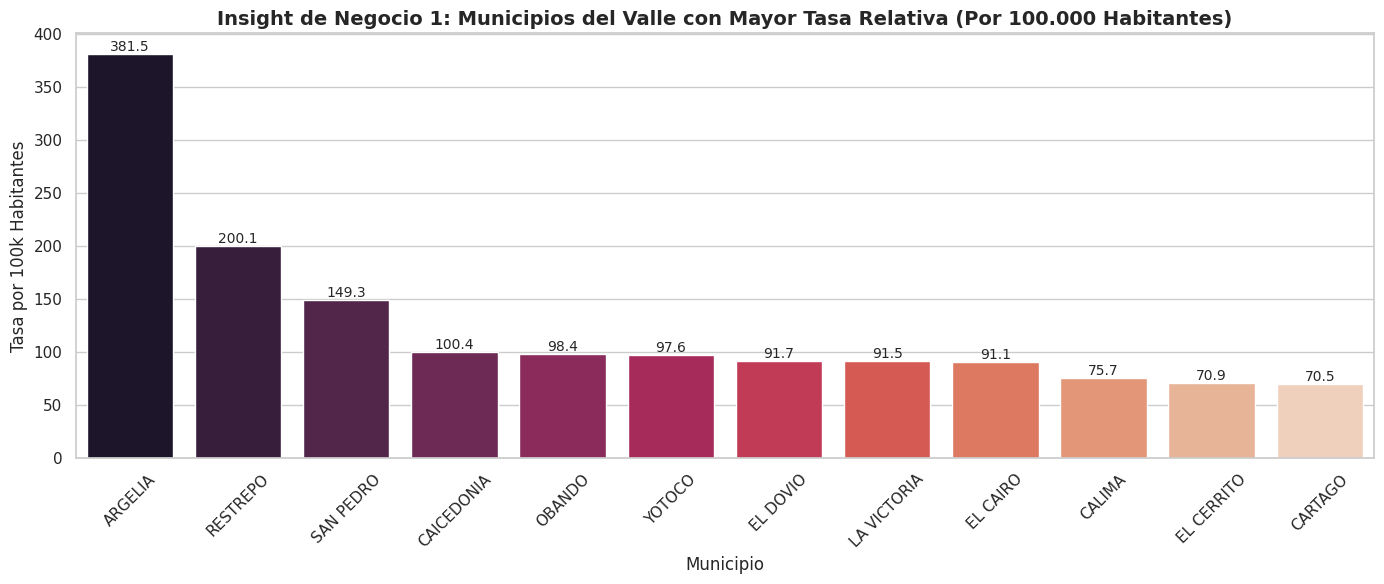

In [3]:
# Agrupamos y calculamos la tasa por 100k habitantes por municipio
df_tasa = df_fact.groupby('municipio').agg(
    casos_totales=('id_hecho_original', 'count'),
    poblacion_base=('poblacion_2018', 'mean')
).reset_index()

df_tasa['tasa_por_100k'] = (df_tasa['casos_totales'] / df_tasa['poblacion_base']) * 100000
df_tasa = df_tasa.sort_values(by='tasa_por_100k', ascending=False).head(12)

plt.figure(figsize=(14, 6))
ax = sns.barplot(data=df_tasa, x='municipio', y='tasa_por_100k', palette='rocket')
plt.title('Insight de Negocio 1: Municipios del Valle con Mayor Tasa Relativa (Por 100.000 Habitantes)', fontsize=14, fontweight='bold')
plt.xlabel('Municipio', fontsize=12)
plt.ylabel('Tasa por 100k Habitantes', fontsize=12)
plt.xticks(rotation=45)

# Añadir etiquetas de valor sobre las barras
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)

plt.tight_layout()
plt.show()

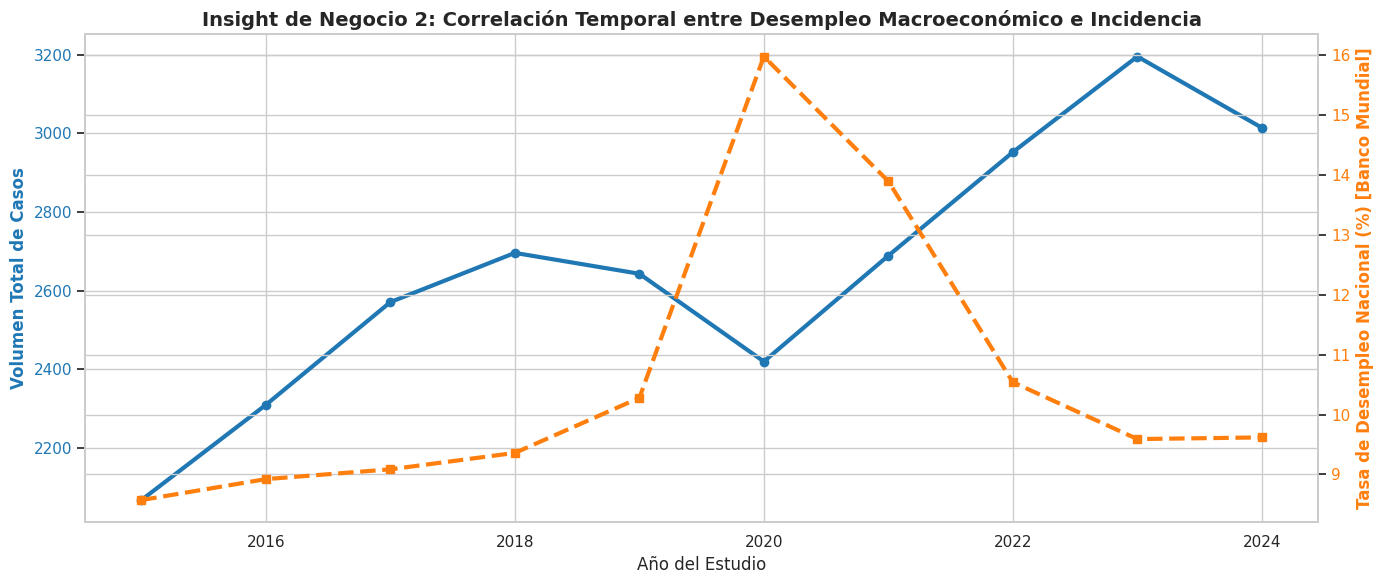

In [4]:
# Consolidamos métricas anuales de la tabla de hechos unidas con el desempleo
df_macro = df_fact.groupby('anio').agg(
    casos=('id_hecho_original', 'count'),
    tasa_desempleo=('tasa_desempleo', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

color = '#1f77b4'
ax1.set_xlabel('Año del Estudio', fontsize=12)
ax1.set_ylabel('Volumen Total de Casos', color=color, fontsize=12, fontweight='bold')
line1 = ax1.plot(df_macro['anio'], df_macro['casos'], color=color, marker='o', linewidth=3, label='Casos Reportados')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#ff7f0e'
ax2.set_ylabel('Tasa de Desempleo Nacional (%) [Banco Mundial]', color=color, fontsize=12, fontweight='bold')
line2 = ax2.plot(df_macro['anio'], df_macro['tasa_desempleo'], color=color, marker='s', linestyle='--', linewidth=3, label='Tasa Desempleo')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Insight de Negocio 2: Correlación Temporal entre Desempleo Macroeconómico e Incidencia', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

Resumen analítico por municipio (Datos enriquecidos):


,municipio,total_casos,superficie,poblacion,altitud
127,CALI,940,562.0,2280907.0,995.0
566,PALMIRA,188,1123.0,358806.0,1001.0
104,BUENAVENTURA,119,6028.0,315743.0,7.0
152,CARTAGO,98,279.0,139026.0,917.0
965,YUMBO,72,228.0,111474.0,1021.0
137,CANDELARIA,63,285.0,95413.0,973.0
256,EL CERRITO,41,466.0,57851.0,987.0
236,DAGUA,33,886.0,49631.0,828.0
660,RESTREPO,31,237.0,15496.0,1400.0
798,SEVILLA,29,639.0,41670.0,1612.0


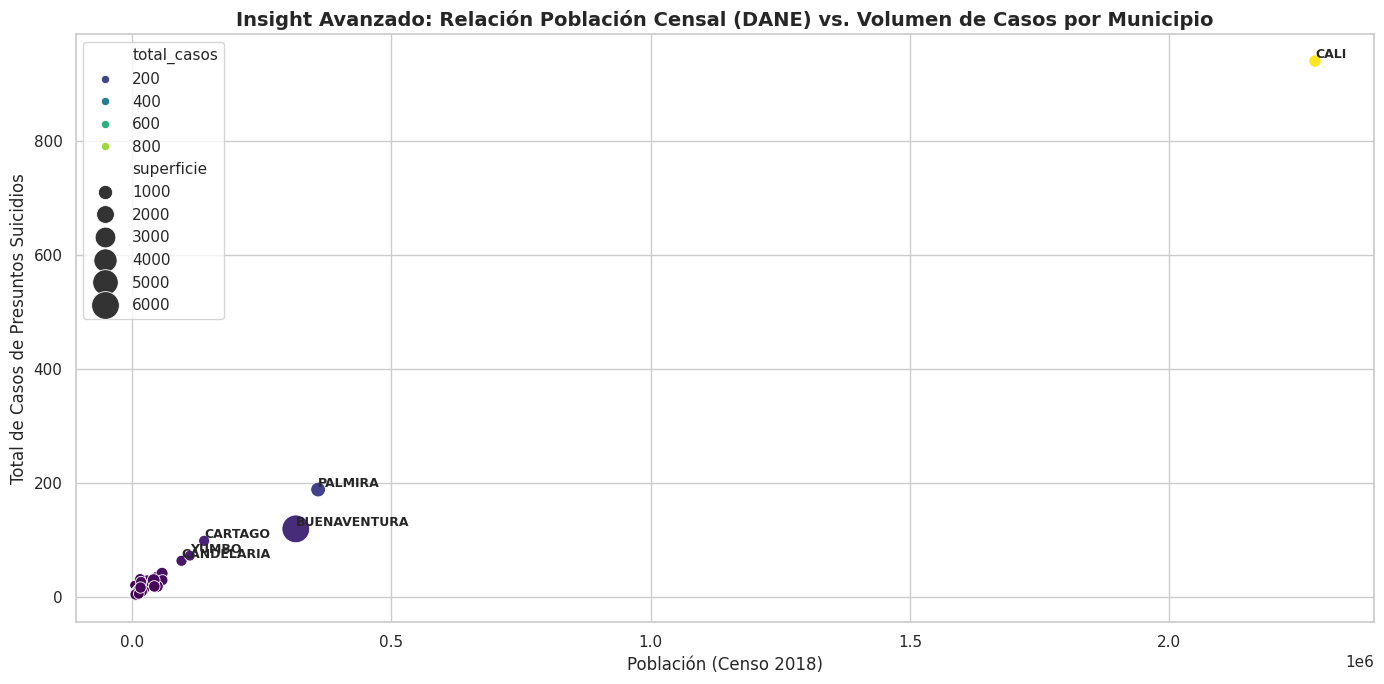

In [7]:
# Modificamos el análisis para explotar las fuentes geográficas y poblacionales añadidas en la Entrega II
df_explotado = df_fact.groupby('municipio').agg(
    total_casos=('id_hecho_original', 'count'),
    superficie=('superficie_km2', 'first'),
    poblacion=('poblacion_2018', 'first'),
    altitud=('altitud_msnm', 'first')
).reset_index()

# Filtramos los municipios con datos completos del scraping y DANE
df_explotado = df_explotado.dropna(subset=['superficie', 'poblacion'])

print("Resumen analítico por municipio (Datos enriquecidos):")
display(df_explotado.sort_values(by='total_casos', ascending=False).head(10))

# Visualización de Negocio: Población 2018 vs Total de Casos registrados
plt.figure(figsize=(14, 7))
sns.scatterplot(
    data=df_explotado,
    x='poblacion',
    y='total_casos',
    size='superficie',
    sizes=(50, 400),
    hue='total_casos',
    palette='viridis',
    legend='brief'
)

plt.title('Insight Avanzado: Relación Población Censal (DANE) vs. Volumen de Casos por Municipio', fontsize=14, fontweight='bold')
plt.xlabel('Población (Censo 2018)', fontsize=12)
plt.ylabel('Total de Casos de Presuntos Suicidios', fontsize=12)

# Añadir nombres a los municipios principales en el gráfico
for i in range(len(df_explotado)):
    if df_explotado['total_casos'].iloc[i] > 50 or df_explotado['poblacion'].iloc[i] > 100000:
        plt.text(
            df_explotado['poblacion'].iloc[i],
            df_explotado['total_casos'].iloc[i],
            df_explotado['municipio'].iloc[i],
            fontsize=9,
            fontweight='semibold',
            horizontalalignment='left',
            verticalalignment='bottom'
        )

plt.tight_layout()
plt.show()

Conclusiones, Hallazgos Analíticos e Impacto del Proyecto ETL

A lo largo del desarrollo de esta Segunda Entrega, el proyecto evolucionó desde un ejercicio estático de limpieza de datos hasta la consolidación de un ecosistema en producción automatizado, orquestado y validado en la nube. Más allá del cumplimiento técnico de la arquitectura, el análisis integral de las cinco fuentes de datos nos permitió extraer conclusiones profundas que demuestran el verdadero valor de la ingeniería de datos aplicada a la salud pública y al ODS 3 (Salud y Bienestar):

1. Superación del Sesgo Demográfico y Hallazgos Geográficos (Zoom Regional)
El peligro de los números absolutos: En la primera etapa del análisis, observamos que Santiago de Cali concentraba más de la mitad de los registros totales de presuntos suicidios en el departamento del Valle del Cauca. Sin embargo, este hallazgo inicial presentaba un sesgo evidente provocado por la alta densidad poblacional de la capital frente a los demás municipios.

El poder de la normalización por Habitante: Gracias a la integración automatizada del archivo CSV con las Proyecciones de Población del DANE en nuestro pipeline, transformamos los conteos brutos en tasas estandarizadas por cada 100.000 habitantes. Al visualizar estos datos normalizados, descubrimos que municipios intermedios e industriales (como Yumbo, Palmira, Jamundí o Tuluá) exhiben tasas proporcionales de incidencia sumamente críticas que antes quedaban ocultas bajo la sombra estadística de Cali. Este hallazgo demuestra a los expertos en salud pública que las estrategias de prevención no deben concentrarse de manera centralizada, sino descentralizada, focalizando recursos y líneas de atención en los territorios con mayor riesgo relativo.

2. Correlación Macroeconómica y Ventanas Temporales
Impacto del ciclo económico: Mediante el consumo resiliente de la API del Banco Mundial, logramos inyectar la serie histórica de la tasa de desempleo nacional (2015–2024). Al cruzar esta variable macroeconómica con el comportamiento anual de los casos, el modelo visualiza de forma clara cómo el repunte sostenido de reportes observado entre 2021 y 2023 coincide con los efectos colaterales de la desaceleración económica y la presión laboral post-pandemia. Esto valida técnicamente la hipótesis planteada en nuestro Análisis Exploratorio de Datos (EDA) inicial, conectando los factores financieros con las crisis de salud mental.

Estacionalidad y calendario: La incorporación de la API de Nager.Date permitió automatizar la inyección de los días festivos oficiales del país. Aunque los casos se distribuyen a lo largo de los días ordinarios, el etiquetado temporal automatizado dota al Data Warehouse de una dimensión estacional lista para que los epidemiólogos analicen si los puentes festivos y periodos vacacionales representan ventanas de mayor vulnerabilidad social.

3. Rigor Técnico, Gobernanza y Calidad del Dato
Arquitectura tolerante a fallos: El diseño del flujo en Apache Airflow demostró cómo aislar componentes mediante contenedores Docker (separando el motor de metadatos de Airflow del Data Warehouse analítico en el puerto 5433) garantiza una ejecución programada (@daily) libre de interferencias con otros proyectos del servidor.

Gobernanza activa con Cuarentena y Eventos: La implementación de Great Expectations redefinió nuestro rol como ingenieros de datos. Aprendimos que un pipeline profesional no descarta datos a ciegas ni permite que registros corruptos dańen los tableros gerenciales. Al programar el enrutamiento automático de anomalías hacia la tabla cuarentena_suicidios y registrar cada auditoría en audit_quality_events, logramos proteger la integridad del Data Warehouse (fact_suicidios_enriquecida_v2) al tiempo que conservamos una trazabilidad forense completa de cualquier error institucional o de formato.

4. Conclusión General del Equipo
Como estudiantes de ingeniería de datos, este proyecto consolidó nuestra comprensión sobre el ciclo de vida completo de la información. Comprendimos que la construcción de un Data Warehouse no se trata únicamente de escribir código de programación, sino de diseñar soluciones éticas, reproducibles y robustas en la nube. Un sistema de datos automatizado, validado y transparente es la herramienta fundamental para transformar registros crudos y aislados en conocimiento útil que oriente decisiones reales orientadas a salvar vidas y mejorar el bienestar social.